# Load initial

In [1]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
GTE_DIR=os.environ["GTE_DIR"]
from glaciation_time_estimator.auxiliary_func.config_reader import read_config
from glaciation_time_estimator.auxiliary_func.Helper_fun import float_range
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import cmcrameri.cm
from glaciation_time_estimator.auxiliary_func.chunking_data import ChunkLoader
import datetime as dt

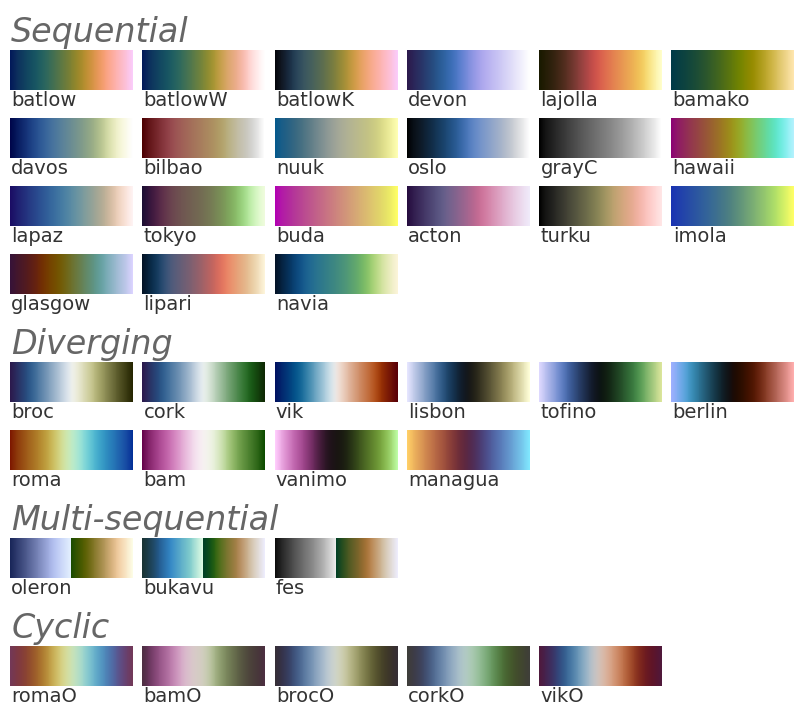

In [2]:
cmcrameri.cm.show_cmaps()

In [3]:
colormap = cmcrameri.cm.lipariS

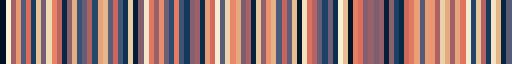

In [4]:
colormap

In [38]:
color_low_res = colormap(0)
color_high_res = colormap(4)
# color_model_old_wbf = colormap(3)
# color_model_new_wbf = colormap(2)
colors_model = {"ICON": 
                    {"v1": colormap(3)
                        ,
                    "v3": colormap(2)
                        },
                "CESM":
                    {"cal": colormap(5),
                     "ootb": colormap(6)
                        },
                }

In [24]:
labels_model = {"ICON": 
                    {"v1": "ICON 160 km instant WBF"
                        ,
                    "v3": "ICON 160 km rate-limited WBF"
                        },
                "CESM":
                    {"ootb": "CESM 1 deg OOTB",
                     "cal": "CESM 1 deg Calibrated",
                        },
                }

In [49]:
glac_threshold=0.4
def calculate_pole_temp_occurance_rate(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk,values='is_glaciating' ,index=["Hemisphere"], columns=["min_temp"], aggfunc='mean')
def calculate_pole_temp_occurance_rate_glac_possible(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk[cloud_chunk.max_water_frac > glac_threshold],values='is_glaciating' ,index=["Hemisphere"], columns=["min_temp"], aggfunc='mean')
def calculate_temp_occurance_rate_glac_possible(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk[cloud_chunk.max_water_frac > glac_threshold],values='is_glaciating', columns=["min_temp"], aggfunc='mean')



# 1 Load data

CLAAS data (1 degree)

In [26]:
# glac_low_res_01 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_Glaciations_20080901.0000_20080914.2345.parquet")
# glac_low_res_02 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_Glaciations_20080915.0000_20080930.2345.parquet")
# glac_low_res = pd.concat([glac_low_res_01,glac_low_res_02],axis=0,ignore_index=True)
# clouds_low_res_01 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_clouds_20080901.0000_20080914.2345.parquet")
# clouds_low_res_02 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_clouds_20080915.0000_20080930.2345.parquet")
# clouds_low_res = pd.concat([clouds_low_res_01,clouds_low_res_02],axis=0,ignore_index=True)


CLAAS data (original - 0.15)

In [27]:
config_claas_low_res = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/Low_resolution_tests/Agg_30/config_n2o.yaml")
# config_claas_low_res = read_config("/cluster/work/climate/dnikolo/n2o/Glaciation_time_estimator/configs/Low_resolution_tests/Agg_30/2007_tracking/01_01.yaml")
loader_claas_low_res = ChunkLoader([2007],config_claas_low_res,filter=True)


Cloud_fps: {2007: '/wolke_scratch/dnikolo/GTE_Results/Low_resolution/Final_results/2007_all.parquet'}


KeyboardInterrupt: 

In [ ]:
config_claas_high_res = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/config_n2o.yaml")
# config_claas_high_res = read_config("/cluster/work/climate/dnikolo/n2o/Glaciation_time_estimator/configs/config_euler.yaml")
loader_claas_high_res = ChunkLoader([2007],config_claas_high_res,filter=True)

Cloud_fps: {2007: '/wolke_scratch/dnikolo/GTE_Results/Final_results/2007_all.parquet'}
All temp ranges covered for year 2007.


In [ ]:
config_r2b4_v1 = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/ICON_output/no_nudging/R2B4/wbf_v1/template.yaml")
loader_r2b4_v1 = ChunkLoader([2007],config_r2b4_v1,filter=True)

Cloud_fps: {2007: '/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/wbf_v1/postprocessing_output/Final_results/2007_all.parquet'}



Missing cloud coverage for year 2007:
  month=04, half=16-end, temp=-36
  month=04, half=16-end, temp=-30
  month=04, half=16-end, temp=-24
  month=04, half=16-end, temp=-18
  month=04, half=16-end, temp=-12
  month=04, half=16-end, temp=-6


In [ ]:
config_r2b4_v3 = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/ICON_output/no_nudging/R2B4/wbf_v3/template.yaml")
loader_r2b4_v3 = ChunkLoader([2007],config_r2b4_v3,filter=True)

Cloud_fps: {2007: '/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/wbf_v3/postprocessing_output/Final_results/2007_all.parquet'}

Missing cloud coverage for year 2007:
  month=04, half=16-end, temp=-36
  month=04, half=16-end, temp=-30
  month=04, half=16-end, temp=-24
  month=04, half=16-end, temp=-18
  month=04, half=16-end, temp=-12
  month=04, half=16-end, temp=-6


In [ ]:
config_cesm_cal = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/CESM_output/test_01/template.yaml")
loader_cesm_cal = ChunkLoader([2000],config_cesm_cal,filter=True)

Cloud_fps: {2000: '/nfs/ch4/wolke_scratch/dnikolo/CESM_Data/test_01/postprocessing_output/Final_results/2000_all.parquet'}

Missing cloud coverage for year 2000:
  month=12, half=16-end, temp=-36
  month=12, half=16-end, temp=-30
  month=12, half=16-end, temp=-24
  month=12, half=16-end, temp=-18
  month=12, half=16-end, temp=-12
  month=12, half=16-end, temp=-6


In [ ]:
config_cesm_ootb = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/CESM_output/ootb/template.yaml")
loader_cesm_ootb = ChunkLoader([2000],config_cesm_ootb,filter=True)

Cloud_fps: {2000: '/nfs/ch4/wolke_scratch/dnikolo/CESM_Data/ootb/postprocessing_output/Final_results/2000_all.parquet'}

Missing cloud coverage for year 2000:
  month=12, half=16-end, temp=-36
  month=12, half=16-end, temp=-30
  month=12, half=16-end, temp=-24
  month=12, half=16-end, temp=-18
  month=12, half=16-end, temp=-12
  month=12, half=16-end, temp=-6


In [28]:
[loader_r2b4_v1.glac_chunk["Hemisphere"]=="South"]

[0         False
 1         False
 2         False
 4         False
 6         False
           ...  
 420595     True
 420596     True
 420597     True
 420598     True
 420601     True
 Name: Hemisphere, Length: 271348, dtype: bool]

In [29]:
model_results = {"ICON": 
                    {"v1": 
                        {"cloud": loader_r2b4_v1.cloud_chunk,
                        "glac": loader_r2b4_v1.glac_chunk[loader_r2b4_v1.glac_chunk["Hemisphere"]=="South"]
                    },
                    "v3":
                        {"cloud": loader_r2b4_v3.cloud_chunk,
                        "glac": loader_r2b4_v3.glac_chunk[loader_r2b4_v3.glac_chunk["Hemisphere"]=="South"]
                    }},
                "CESM":
                    {"ootb": 
                        {"cloud": loader_cesm_ootb.cloud_chunk,
                        "glac": loader_cesm_ootb.glac_chunk[loader_cesm_ootb.glac_chunk["Hemisphere"]=="South"]
                    },
                    "cal": 
                        {"cloud": loader_cesm_cal.cloud_chunk,
                        "glac": loader_cesm_cal.glac_chunk[loader_cesm_cal.glac_chunk["Hemisphere"]=="South"]
                    }},
                }

Model 160 km

clouds_model.sample(10000,random_state=1).equals(clouds_model_new_wbf.sample(10000,random_state=1))

In [30]:
glac_high_res = loader_claas_high_res.glac_chunk
clouds_high_res = loader_claas_high_res.cloud_chunk
glac_low_res = loader_claas_low_res.glac_chunk
clouds_low_res = loader_claas_low_res.cloud_chunk

In [31]:
test_values = np.concatenate(model_results["CESM"]["ootb"]["cloud"]["ice_frac_hist"].to_numpy())

In [32]:
test_values.min()

0.0

In [33]:
start_time=pd.Timestamp("2008-09-01")
end_time= pd.Timestamp("2008-09-08")
def time_filter(df):
    return df[(df.track_start_time>=start_time) & (df.track_start_time<end_time)]
def get_peak_if(glac_df_row):
    return glac_df_row["ice_frac_hist"][glac_df_row["Glac_peak_ind"]]
def set_peak_if(glac_df):
    glac_df["Peak IF"] = glac_df.apply(get_peak_if,axis=1)
def filter_df(df):
    return df[(~df.is_large_pix_cloud) & (abs(df.avg_lat)>30)]
def preproc_glac(glac_df):
    set_peak_if(glac_df)
    return filter_df(time_filter(glac_df))
def preproc_cloud(cloud_df):
    return filter_df(time_filter(cloud_df))

set_peak_if(glac_high_res)
set_peak_if(glac_low_res)

for resolution, wbf in model_results.items():
    for wbf, variables in wbf.items():
        print(resolution, wbf)
        set_peak_if(variables["glac"])

ICON v1


/tmp/ipykernel_2530362/2276321234.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  glac_df["Peak IF"] = glac_df.apply(get_peak_if,axis=1)


ICON v3


/tmp/ipykernel_2530362/2276321234.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  glac_df["Peak IF"] = glac_df.apply(get_peak_if,axis=1)


CESM ootb
CESM cal


/tmp/ipykernel_2530362/2276321234.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  glac_df["Peak IF"] = glac_df.apply(get_peak_if,axis=1)
/tmp/ipykernel_2530362/2276321234.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  glac_df["Peak IF"] = glac_df.apply(get_peak_if,axis=1)


# Plots

Mean for ICON_v1 is 275.98391297350287 +- 326.48585504698934
Median:180.0
Mean for ICON_v3 is 293.74115854581413 +- 346.3904720927971
Median:180.0
Mean for CESM_ootb is 291.72098442288046 +- 413.54438347421143
Median:150.0
Mean for CESM_cal is 270.6750154820065 +- 349.30738973247844
Median:150.0


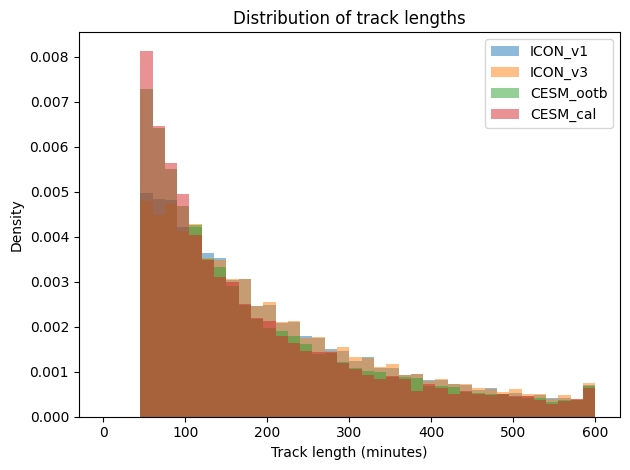

In [39]:
for resolution, wbf in model_results.items():
    for wbf, variables in wbf.items():
        # Dict values are timedeltas
        vals = np.array(list(variables["glac"].track_length.values))
        # Convert timedeltas to minutes
        minutes = vals.astype("timedelta64[s]").astype(float) / 60
        print(f"Mean for {resolution}_{wbf} is {minutes.mean()} +- {minutes.std()}")
        print(f"Median:{np.median(minutes)}")
        plt.hist(minutes, bins=40,range=[0,600],density=True,alpha=0.5, label=f"{resolution}_{wbf}")
plt.xlabel("Track length (minutes)")
plt.ylabel("Density")
plt.title("Distribution of track lengths")
plt.legend()
plt.tight_layout()
plt.show()


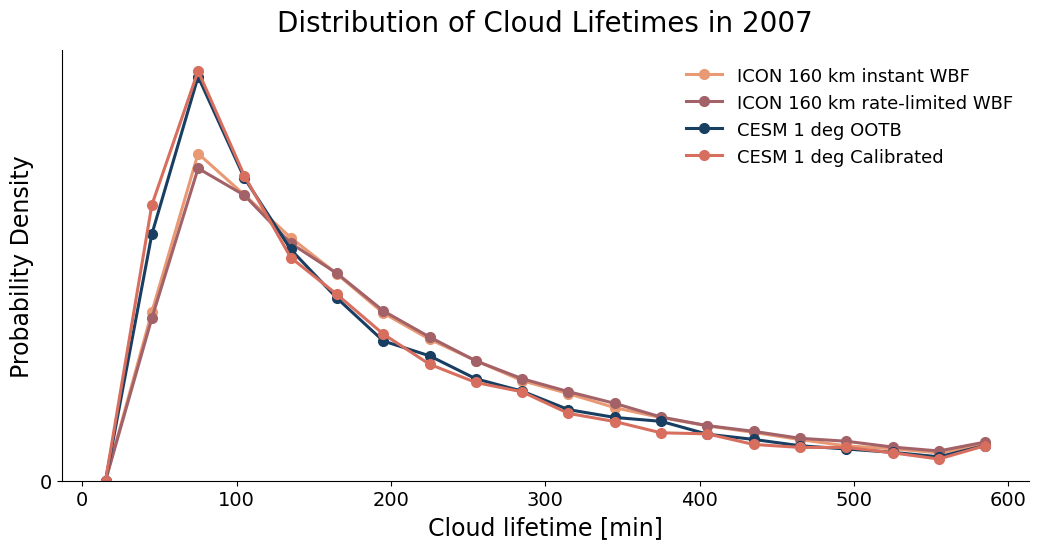

In [40]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
# fig.patch.set_alpha(0)
ax.set_facecolor("none")

bins = 20
hist_range = [0, 600]

# ICON model results
for resolution, wbf_results in model_results.items():
    for wbf, variables in wbf_results.items():
        vals_model = np.array(list(variables["glac"].track_length.values))
        minutes_model = vals_model.astype("timedelta64[s]").astype(float) / 60

        counts_model, edges_model = np.histogram(
            minutes_model[~np.isnan(minutes_model)],
            bins=bins,
            range=hist_range,
            density=True
        )
        centers_model = 0.5 * (edges_model[:-1] + edges_model[1:])

        ax.plot(
            centers_model,
            counts_model,
            "-o",
            label=f"{labels_model[resolution][wbf]}",
            color=colors_model[resolution][wbf],
            linewidth=2.2,
            markersize=7
        )

ax.set_title(
    "Distribution of Cloud Lifetimes in 2007",
    fontsize=20,
    pad=14
)

ax.set_xlabel("Cloud lifetime [min]", fontsize=17)
ax.set_ylabel("Probability Density", fontsize=17)

# X-axis tick size
ax.tick_params(axis="x", labelsize=14)

# Show only the 0 tick on the vertical axis
ax.set_ylim(bottom=0)
ax.set_yticks([0])
ax.tick_params(axis="y", labelsize=14, left=True, right=False, labelleft=True)

# Legend
ax.legend(
    fontsize=13,
    frameon=False,
    loc="best"
)

# Remove top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Cleaner spacing
plt.tight_layout()

plt.savefig(
    "/wolke_scratch/dnikolo/MSGI/figures/cloud_lifetime_distribution_no_nudging.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300
)

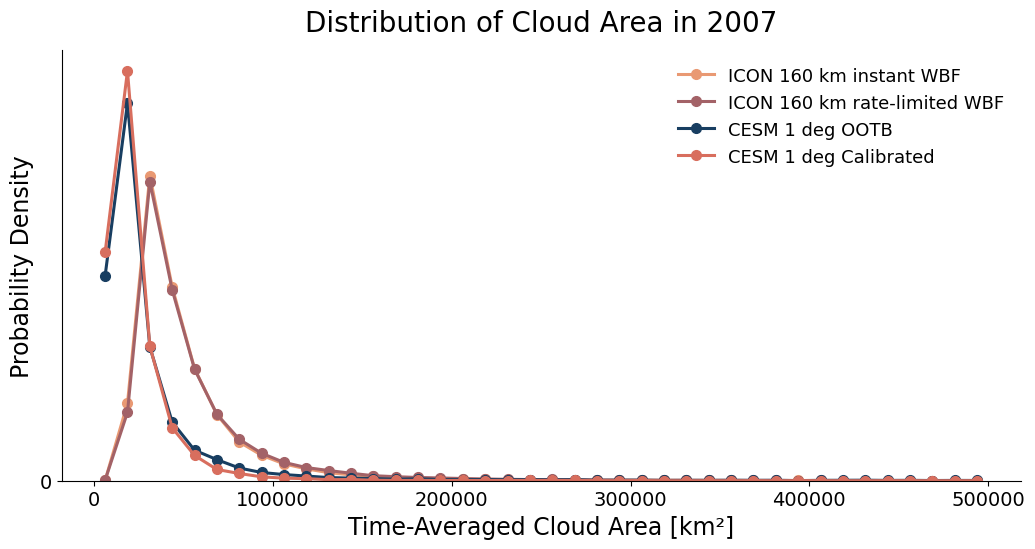

In [41]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
# fig.patch.set_alpha(0)
# ax.set_facecolor("none")

bins = 40
hist_range = [0, 5e5]

# ICON model results
for resolution, wbf_results in model_results.items():
    for wbf, variables in wbf_results.items():
        area_model = variables["glac"]["avg_size[km]"].dropna().to_numpy()

        counts_model, edges_model = np.histogram(
            area_model,
            bins=bins,
            range=hist_range,
            density=True
        )
        centers_model = 0.5 * (edges_model[:-1] + edges_model[1:])

        ax.plot(
            centers_model,
            counts_model,
            "-o",
            label=f"{labels_model[resolution][wbf]}",
            color=colors_model[resolution][wbf],
            linewidth=2.2,
            markersize=7
        )

ax.set_title(
    "Distribution of Cloud Area in 2007",
    fontsize=20,
    pad=14
)

ax.set_xlabel("Time-Averaged Cloud Area [km²]", fontsize=17)
ax.set_ylabel("Probability Density", fontsize=17)

# X-axis tick size
ax.tick_params(axis="x", labelsize=14)

# Show only the 0 tick on the vertical axis
ax.set_ylim(bottom=0)
ax.set_yticks([0])
ax.tick_params(axis="y", labelsize=14, left=True, right=False, labelleft=True)

# Legend
ax.legend(
    fontsize=13,
    frameon=False,
    loc="best"
)

# Remove top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Cleaner spacing
plt.tight_layout()

plt.savefig(
    "/wolke_scratch/dnikolo/MSGI/figures/avg_cloud_area_distribution_no_nudging.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300
)

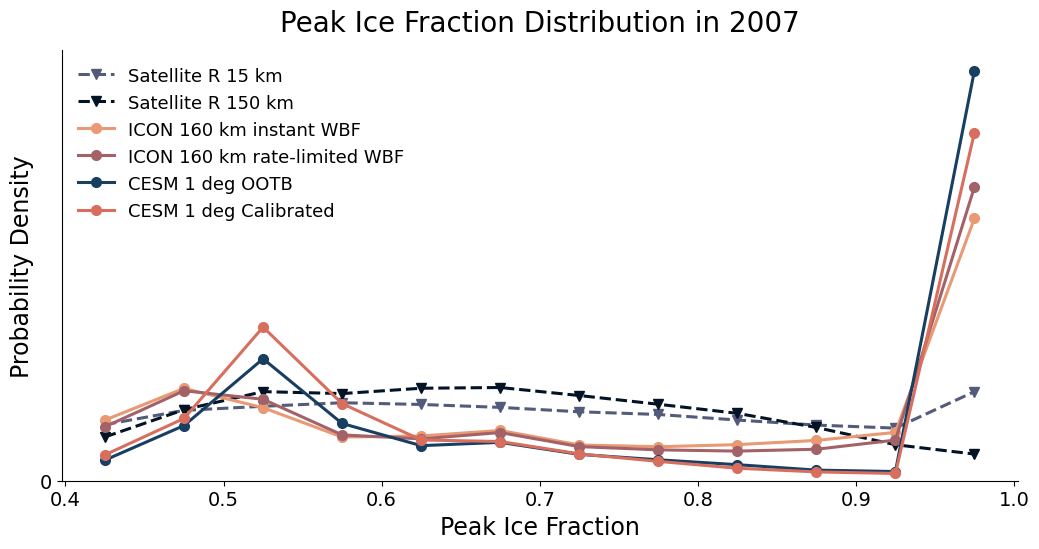

In [42]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
# fig.patch.set_alpha(0)
# ax.set_facecolor("none")

bins = 12

# CLAAS High Res
counts_hr, edges_hr = np.histogram(
    glac_high_res["Peak IF"].dropna(),
    bins=bins,
    range=[0.4, 1],
    density=True
)
centers_hr = 0.5 * (edges_hr[:-1] + edges_hr[1:])
ax.plot(
    centers_hr, counts_hr,
    "--v",
    label="Satellite R 15 km",
    color=color_high_res,
    linewidth=2.2,
    markersize=7
)

# CLAAS
counts_lr, edges_lr = np.histogram(
    glac_low_res["Peak IF"].dropna(),
    bins=bins,
    range=[0.4, 1],
    density=True
)
centers_lr = 0.5 * (edges_lr[:-1] + edges_lr[1:])
ax.plot(
    centers_lr, counts_lr,
    "--v",
    label="Satellite R 150 km",
    color=color_low_res,
    linewidth=2.2,
    markersize=7
)

for resolution, wbf in model_results.items():
    for wbf, variables in wbf.items():
        # Dict values are timedeltas
        # vals = np.array(list(variables["glac"].track_length.values))
        # Convert timedeltas to minutes
        counts2, edges2 = np.histogram(
            variables["glac"]["Peak IF"].dropna(),
            bins=bins,
            range=[0.4, 1],
            density=True
        )
        centers2 = 0.5 * (edges2[:-1] + edges2[1:])
        ax.plot(
            centers2, counts2,
            "-o",
            label=f"{labels_model[resolution][wbf]}",
            color=colors_model[resolution][wbf],
            linewidth=2.2,
            markersize=7
        )
        

ax.set_title(
    "Peak Ice Fraction Distribution in 2007",
    fontsize=20,
    pad=14
)

ax.set_xlabel("Peak Ice Fraction", fontsize=17)
ax.set_ylabel("Probability Density", fontsize=17)

# X-axis tick size
ax.tick_params(axis="x", labelsize=14)

# Show only the 0 tick on the vertical axis
ax.set_ylim(bottom=0)
ax.set_yticks([0])
ax.tick_params(axis="y", labelsize=14, left=True, right=False, labelleft=True)

# Legend
ax.legend(
    fontsize=13,
    frameon=False,
    loc="best"
)

# Remove top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# Cleaner spacing
plt.tight_layout()

# plt.savefig(
#     "/wolke_scratch/dnikolo/MSGI/figures/peak_if_distribution_no_nudging.png",
#     transparent=True,
#     bbox_inches="tight",
#     dpi=300
# )

cmcrameri

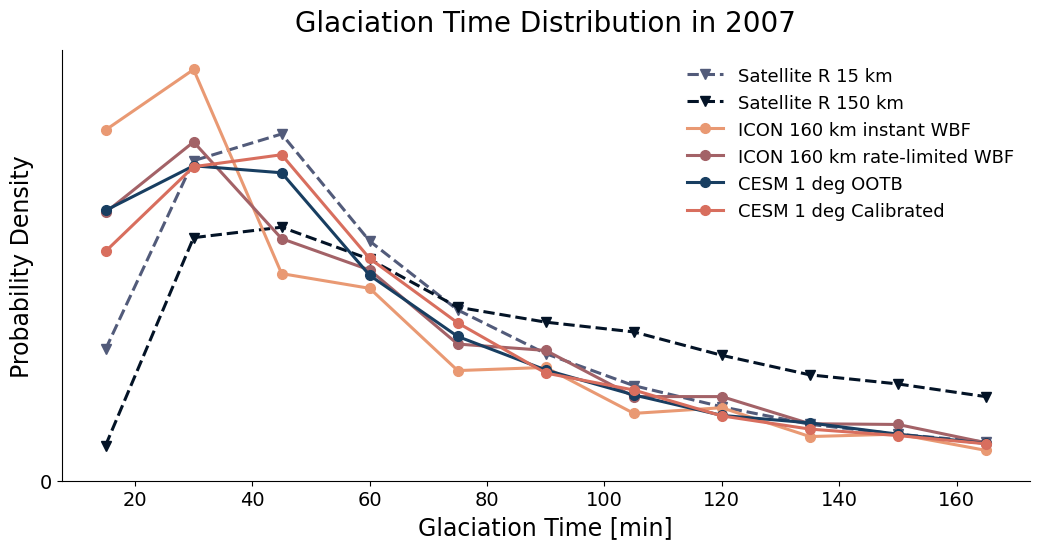

In [43]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
# fig.patch.set_alpha(0)
# ax.set_facecolor("none")

bins = np.arange(7.5, 181, 15)

# Satellite R 15 km
counts_hr, edges_hr = np.histogram(
    glac_high_res["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers_hr = 0.5 * (edges_hr[:-1] + edges_hr[1:])
ax.plot(
    centers_hr, counts_hr,
    "--v",
    label="Satellite R 15 km",
    color=color_high_res,
    linewidth=2.2,
    markersize=7
)

# Satellite R 150 km
counts_lr, edges_lr = np.histogram(
    glac_low_res["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers_lr = 0.5 * (edges_lr[:-1] + edges_lr[1:])
ax.plot(
    centers_lr, counts_lr,
    "--v",
    label="Satellite R 150 km",
    color=color_low_res,
    linewidth=2.2,
    markersize=7
)

# ICON model results
for resolution, wbf_results in model_results.items():
    for wbf, variables in wbf_results.items():
        # if resolution=="r2b5" and wbf == "v3":
        #     continue
        counts_model, edges_model = np.histogram(
            variables["glac"]["Time [m]"].dropna(),
            bins=bins,
            density=True
        )
        centers_model = 0.5 * (edges_model[:-1] + edges_model[1:])

        ax.plot(
            centers_model, counts_model,
            "-o",
            label=f"{labels_model[resolution][wbf]}",
            color=colors_model[resolution][wbf],
            linewidth=2.2,
            markersize=7
        )

ax.set_title(
    "Glaciation Time Distribution in 2007",
    fontsize=20,
    pad=14
)

ax.set_xlabel("Glaciation Time [min]", fontsize=17)
ax.set_ylabel("Probability Density", fontsize=17)

# X-axis tick size
ax.tick_params(axis="x", labelsize=14)

# Show only the 0 tick on the vertical axis
ax.set_ylim(bottom=0)
ax.set_yticks([0])
ax.tick_params(axis="y", labelsize=14, left=True, right=False, labelleft=True)
# Legend
ax.legend(
    fontsize=13,
    frameon=False,
    loc="best"
)

# Remove top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Cleaner spacing
plt.tight_layout()

plt.savefig(
    "/wolke_scratch/dnikolo/MSGI/figures/glaciation_time_distribution_no_nudging.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300
)

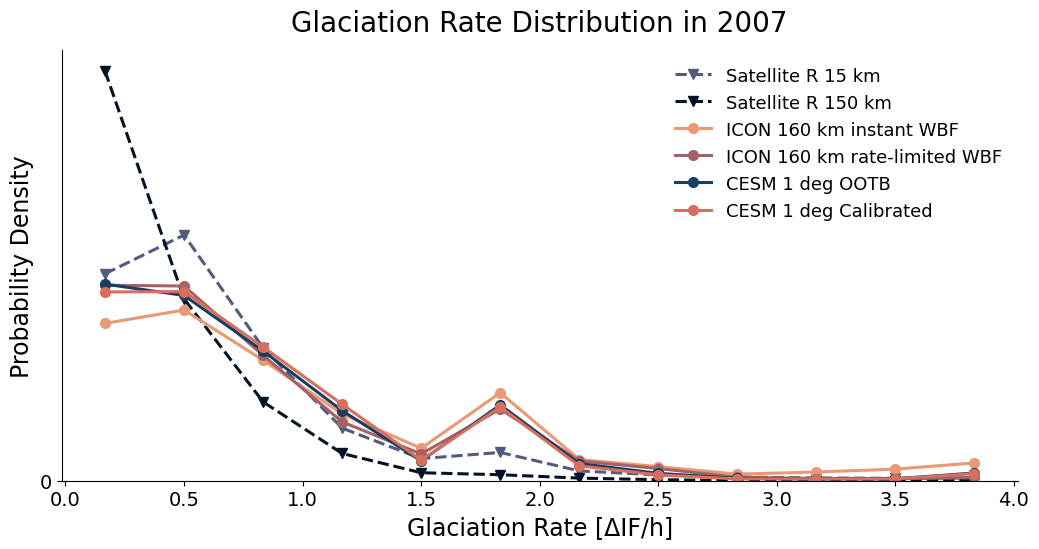

In [44]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
# fig.patch.set_alpha(0)
# ax.set_facecolor("none")

bins = np.linspace(0, 4.0, 13)  # 12 bins

# Satellite R 15 km
rate_hr = glac_high_res["Magnitude"] / (glac_high_res["Time [m]"] / 60)
counts_hr, edges_hr = np.histogram(
    rate_hr.dropna(),
    bins=bins,
    density=True
)
centers_hr = 0.5 * (edges_hr[:-1] + edges_hr[1:])
ax.plot(
    centers_hr, counts_hr,
    "--v",
    label="Satellite R 15 km",
    color=color_high_res,
    linewidth=2.2,
    markersize=7
)

# Satellite R 150 km
rate_lr = glac_low_res["Magnitude"] / (glac_low_res["Time [m]"] / 60)
counts_lr, edges_lr = np.histogram(
    rate_lr.dropna(),
    bins=bins,
    density=True
)
centers_lr = 0.5 * (edges_lr[:-1] + edges_lr[1:])
ax.plot(
    centers_lr, counts_lr,
    "--v",
    label="Satellite R 150 km",
    color=color_low_res,
    linewidth=2.2,
    markersize=7
)

# ICON model results
for resolution, wbf_results in model_results.items():
    for wbf, variables in wbf_results.items():
        rate_model = (
            variables["glac"]["Magnitude"]
            / (variables["glac"]["Time [m]"] / 60)
        )

        counts_model, edges_model = np.histogram(
            rate_model.dropna(),
            bins=bins,
            density=True
        )
        centers_model = 0.5 * (edges_model[:-1] + edges_model[1:])

        ax.plot(
            centers_model, counts_model,
            "-o",
            label=f"{labels_model[resolution][wbf]}",
            color=colors_model[resolution][wbf],
            linewidth=2.2,
            markersize=7
        )

ax.set_title(
    "Glaciation Rate Distribution in 2007",
    fontsize=20,
    pad=14
)

ax.set_xlabel("Glaciation Rate [ΔIF/h]", fontsize=17)
ax.set_ylabel("Probability Density", fontsize=17)

# X-axis tick size
ax.tick_params(axis="x", labelsize=14)

# Show only the 0 tick on the vertical axis
ax.set_ylim(bottom=0)
ax.set_yticks([0])
ax.tick_params(axis="y", labelsize=14, left=True, right=False, labelleft=True)

# Legend
ax.legend(
    fontsize=13,
    frameon=False,
    loc="best"
)

# Remove top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Cleaner spacing
plt.tight_layout()

plt.savefig(
    "/wolke_scratch/dnikolo/MSGI/figures/glaciation_rate_distribution_no_nudging.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300
)

In [ ]:
print(calculate_temp_occurance_rate_glac_possible((clouds_high_res, None, None)))
print(calculate_pole_temp_occurance_rate_glac_possible((clouds_low_res, None, None)))

min_temp           -36      -30       -24       -18       -12  -6 
is_glaciating  0.10797  0.05329  0.029931  0.017446  0.004819  0.0
min_temp         -36       -30       -24       -18       -12       -6 
Hemisphere                                                            
North       0.010620  0.010901  0.008524  0.004551  0.001045  0.000000
South       0.018284  0.012705  0.007029  0.003552  0.000777  0.000011


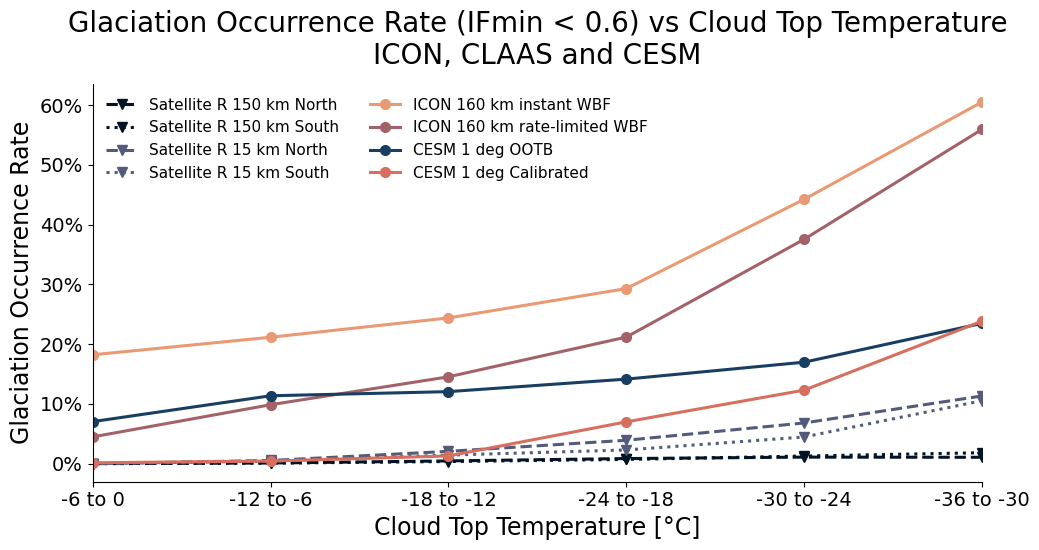

In [45]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
# fig.patch.set_alpha(0)
# ax.set_facecolor("none")

high_res_occ_rate = calculate_pole_temp_occurance_rate_glac_possible(
    (clouds_high_res, None, None)
)
low_res_occ_rate = calculate_pole_temp_occurance_rate_glac_possible(
    (clouds_low_res, None, None)
)

# Satellite R 150 km
ax.plot(
    low_res_occ_rate.columns,
    low_res_occ_rate.loc["North"],
    label="Satellite R 150 km North",
    color=color_low_res,
    linestyle="dashed",
    marker="v",
    linewidth=2.2,
    markersize=7
)
ax.plot(
    low_res_occ_rate.columns,
    low_res_occ_rate.loc["South"],
    label="Satellite R 150 km South",
    color=color_low_res,
    linestyle="dotted",
    marker="v",
    linewidth=2.2,
    markersize=7
)

# Satellite R 15 km
ax.plot(
    high_res_occ_rate.columns,
    high_res_occ_rate.loc["North"],
    label="Satellite R 15 km North",
    color=color_high_res,
    linestyle="dashed",
    marker="v",
    linewidth=2.2,
    markersize=7
)
ax.plot(
    high_res_occ_rate.columns,
    high_res_occ_rate.loc["South"],
    label="Satellite R 15 km South",
    color=color_high_res,
    linestyle="dotted",
    marker="v",
    linewidth=2.2,
    markersize=7
)

# ICON model results
for resolution, wbf_results in model_results.items():
    for wbf, variables in wbf_results.items():
        model_occ_rate = calculate_pole_temp_occurance_rate_glac_possible(
            (variables["cloud"], None, None)
        )

        ax.plot(
            model_occ_rate.columns,
            (model_occ_rate.loc["North"]+model_occ_rate.loc["South"])/2,
            label=f"{labels_model[resolution][wbf]}",
            color=colors_model[resolution][wbf],
            # linestyle="dashed",
            marker="o",
            linewidth=2.2,
            markersize=7
        )
        # ax.plot(
        #     model_occ_rate.columns,
        #     model_occ_rate.loc["South"],
        #     label=f"{labels_model[resolution][wbf]} South",
        #     color=colors_model[resolution][wbf],
        #     linestyle="dotted",
        #     marker="o",
        #     linewidth=2.2,
        #     markersize=7
        # )

# Axis limits and direction
ax.set_xlim(-36, -6)
ax.invert_xaxis()

# Title and labels
ax.set_title(
    "Glaciation Occurrence Rate (IFmin < 0.6) vs Cloud Top Temperature\nICON, CLAAS and CESM",
    fontsize=20,
    pad=14
)
ax.set_xlabel("Cloud Top Temperature [°C]", fontsize=17)
ax.set_ylabel("Glaciation Occurrence Rate", fontsize=17)

# Tick formatting
ax.tick_params(axis="x", labelsize=14)
ax.tick_params(axis="y", labelsize=14)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

ax.set_xticks(
    np.arange(-36, -6 + 1, 6),
    labels=[f"{i} to {i + 6}" for i in range(-36, 0, 6)]
)

# Remove top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend
ax.legend(
    fontsize=11,
    frameon=False,
    loc="upper left",
    ncol=2
)

# Cleaner spacing
plt.tight_layout()

# plt.savefig(
#     "/wolke_scratch/dnikolo/MSGI/figures/glaciation_occurrence_rate_vs_ctt_no_nudging.png",
#     transparent=True,
#     bbox_inches="tight",
#     dpi=300
# )

In [55]:
occurrence_results = {}
temp_occurrence_results = {}

# Satellites
for name, clouds in {
    "Satellite R 150 km": clouds_low_res,
    "Satellite R 15 km": clouds_high_res,
}.items():
    pole_rate = calculate_pole_temp_occurance_rate_glac_possible(
        (clouds, None, None)
    )
    temp_rate = calculate_temp_occurance_rate_glac_possible(
        (clouds, None, None)
    )

    occurrence_results[f"{name} North"] = pole_rate.loc["North"]
    occurrence_results[f"{name} South"] = pole_rate.loc["South"]
    temp_occurrence_results[name] = temp_rate.loc["is_glaciating"]

# ICON models
for resolution, wbf_results in model_results.items():
    for wbf, variables in wbf_results.items():
        name = labels_model[resolution][wbf]

        pole_rate = calculate_pole_temp_occurance_rate_glac_possible(
            (variables["cloud"], None, None)
        )
        temp_rate = calculate_temp_occurance_rate_glac_possible(
            (variables["cloud"], None, None)
        )

        # This is the line plotted
        occurrence_results[name] = (
            pole_rate.loc["North"] + pole_rate.loc["South"]
        ) / 2

        temp_occurrence_results[name] = temp_rate.loc["is_glaciating"]

# Save polar/plotted results
pd.DataFrame(occurrence_results).T.to_csv(
    "/wolke_scratch/dnikolo/MSGI/plotting/Publication_figures/data/Occurance_rate/pole_temp_occurrence_rates.csv",
    index_label="Line"
)

# Save total temperature occurrence results
pd.DataFrame(temp_occurrence_results).T.to_csv(
    "/wolke_scratch/dnikolo/MSGI/plotting/Publication_figures/data/Occurance_rate/temp_occurrence_rates.csv",
    index_label="Line"
)

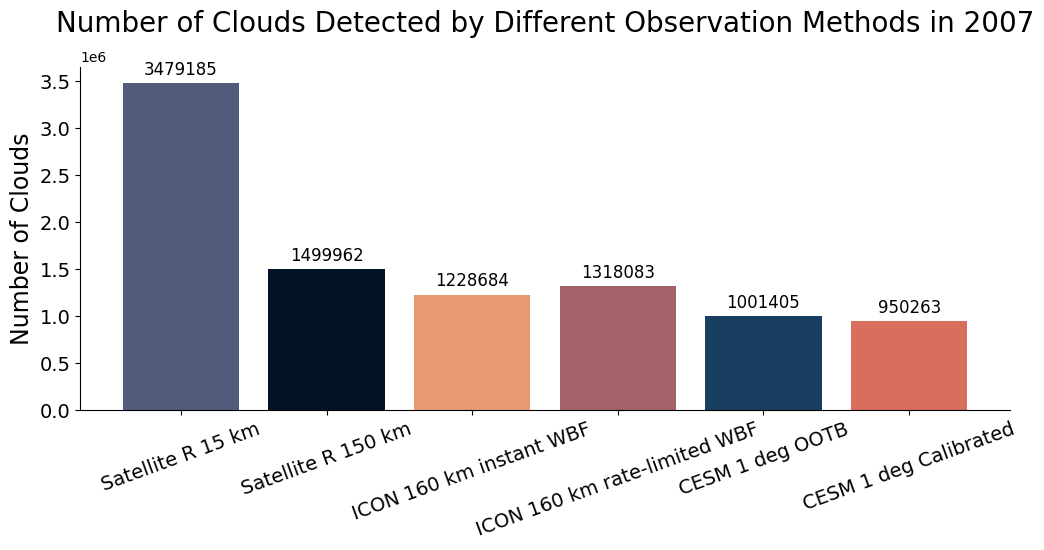

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

# Count rows in each dataframe
counts = pd.DataFrame({
    "Observation method": [
        "Satellite R 15 km",
        "Satellite R 150 km",
    ],
    "Num clouds": [
        len(clouds_high_res),
        len(clouds_low_res),
    ],
    "Color": [
        color_high_res,
        color_low_res,
    ]
})

# Add ICON model results
for resolution, wbf_results in model_results.items():
    for wbf, variables in wbf_results.items():
        counts.loc[len(counts)] = {
            "Observation method": f"{labels_model[resolution][wbf]}",
            "Num clouds": len(variables["cloud"]),
            "Color": colors_model[resolution][wbf],
        }

fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
# fig.patch.set_alpha(0)
ax.set_facecolor("none")

bars = ax.bar(
    counts["Observation method"],
    counts["Num clouds"],
    color=counts["Color"]
)

ax.set_title(
    "Number of Clouds Detected by Different Observation Methods in 2007",
    fontsize=20,
    pad=14
)

ax.set_xlabel("")
ax.set_ylabel("Number of Clouds", fontsize=17)

# Tick formatting
ax.tick_params(axis="x", labelsize=14, rotation=20)
ax.tick_params(axis="y", labelsize=14)

# Add value labels on bars
ax.bar_label(
    bars,
    fmt="%.0f",
    padding=3,
    fontsize=12
)

# Remove top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Cleaner spacing
plt.tight_layout()

plt.savefig(
    "/wolke_scratch/dnikolo/MSGI/figures/num_clouds_by_observation_method_no_nudging.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300
)

In [47]:
import seaborn as sns

NameError: name 'clouds_model' is not defined

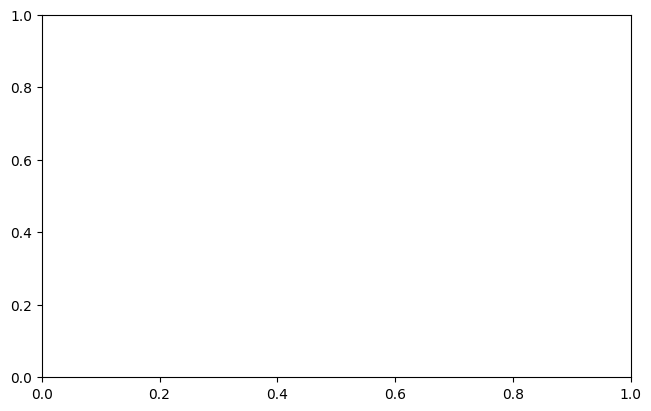

In [48]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
sns.histplot(clouds_model[clouds_model["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="ICON R 160km" )
sns.histplot(clouds_high_res[clouds_high_res["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="Satellite R 15km")
sns.histplot(clouds_low_res[clouds_low_res["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="Satellite R 150km")
ax.set_title('Cloud top area distribution \n for different observation methods in 2007')
plt.legend()
ax.set_xlabel('Cloud top area [km^2]')

In [ ]:
(clouds_high_res["avg_size[km]"]<0.01e7).value_counts(normalize=True)

avg_size[km]
True     0.997858
False    0.002142
Name: proportion, dtype: float64

# Calculations

In [ ]:
(glac_model.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.927476
True     0.072524
Name: proportion, dtype: float64

In [ ]:
(glac_model_new_wbf.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.9605
True     0.0395
Name: proportion, dtype: float64

In [ ]:
(glac_low_res.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.996839
True     0.003161
Name: proportion, dtype: float64

In [ ]:
(glac_high_res.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.992448
True     0.007552
Name: proportion, dtype: float64

In [ ]:
from scipy.signal import savgol_filter

def noise_filter_4(row, w=4, order=2):
    IF_hist = np.array(row['ice_frac_hist'])
    return savgol_filter(IF_hist, w, order)

In [ ]:
se_sum=0
sample_count=0
for i, row in glac_high_res.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.0651292202357399


In [ ]:
se_sum=0
sample_count=0
for i, row in glac_model.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.09630264845824899


In [ ]:
se_sum=0
sample_count=0
for i, row in glac_model.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

In [ ]:
(glac_low_res["Time [m]"]==15).value_counts()

Time [m]
False    1396
True       85
Name: count, dtype: int64

## Deprecated

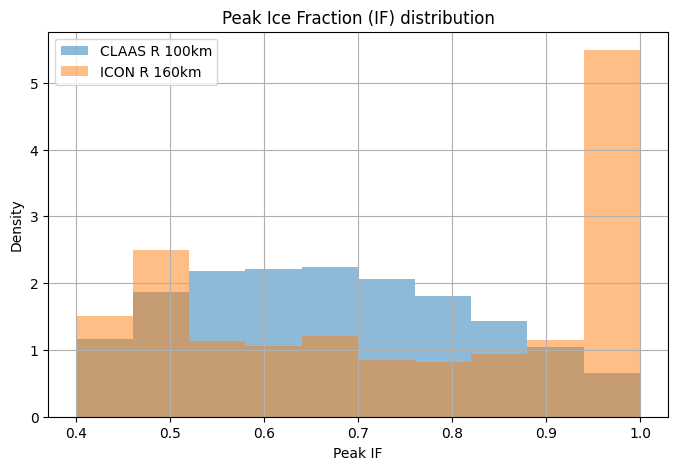

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
glac_low_res["Peak IF"].hist( alpha=0.5, density=True,label="Satellite R 150km")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON Old WBF R 160km")
glac_model["Peak IF"].hist( alpha=0.5, density=True,label="ICON R 160km")
plt.title("Peak Ice Fraction (IF) distribution")
plt.xlabel("Peak IF")
plt.ylabel("Density")
plt.legend()

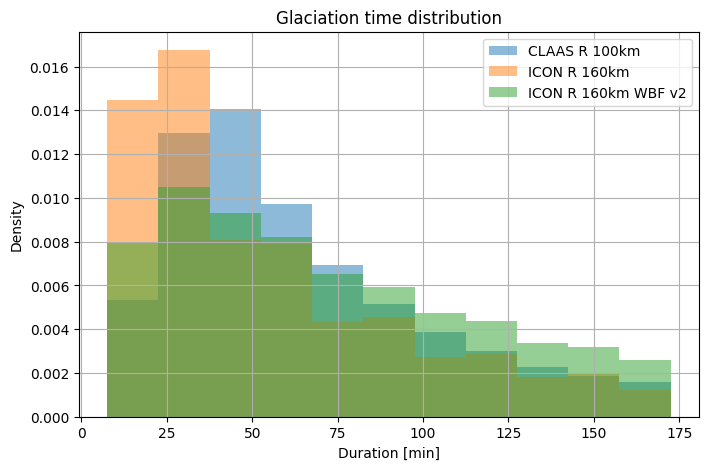

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
# glac_low_res["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="Satellite R 150km")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON Old WBF R 160km")
glac_high_res["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="Satellite R 150km")
glac_model["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 160km")
glac_model_new_wbf["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 160km WBF v2")
# glac_model["Time [m]"].hist( alpha=0.5, density=True,label="ICON R 160km")
plt.title("Glaciation time distribution")
plt.xlabel("Duration [min]")
plt.ylabel("Density")
plt.legend()